# 06 - Figures du papier, version 3 panneaux

Quatre figures, une affirmation chacune, trois panneaux chacune. Style repris de `03_figures.ipynb`
(fond crème, police Inter, cartes Robinson à légende segmentée).

| Figure | Affirmation portée |
|---|---|
| **1** | Le service forestier domine la richesse carbone et il est détenu très inégalement |
| **2** | L'océan change ce que les pays détiennent, pas qui fournit le service |
| **3** | Déforestation déclarée et capacité annuelle d'ajout brut associée |
| **4** | Celui qui perd le puits n'est pas celui qui peut payer |

Règles : les taux forestiers sont les moyennes Gibbs/GFW de gross removals vers la biomasse vivante aérienne et souterraine, par quatre biomes FAO GEZ. Il s’agit d’ajouts bruts annuels, sans bilan net d’écosystème ni durée de stockage implicite. Les valeurs absentes restent absentes .

Les figures sont écrites dans `results/figures/paper_v2/` et n'écrasent pas celles des autres notebooks.

## 0. Style, données et utilitaires

In [1]:
import glob
import os
import zipfile
from pathlib import Path

import geopandas as gpd
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch, Rectangle

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
DATA, OUT = ROOT / "data", ROOT / "output"
SUMMARY = DATA / "summary"
FIGURES = OUT / "figures" / "paper_v2"
FIGURES.mkdir(parents=True, exist_ok=True)
CO2_PER_C = 44 / 12

for path in [r"C:\Windows\Fonts", os.path.expandvars(r"%LOCALAPPDATA%\Microsoft\Windows\Fonts")]:
    for font in glob.glob(os.path.join(path, "*Inter*.ttf")):
        fm.fontManager.addfont(font)

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Inter", "Segoe UI", "DejaVu Sans"],
    "axes.titlesize": 13,
    "axes.labelsize": 11.5,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "text.color": "black",
    "axes.labelcolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
})

# --- palette commune au papier ------------------------------------------------
BG = "#FAFAF7"          # fond crème
TEXT = "black"          # tout le texte des figures est noir
TEXT2 = "#5F6368"    # texte secondaire : annotations
MUTED = "#4D4D4D"       # traits secondaires seulement, jamais du texte
GRID = "#D9DDD9"
EDGE_GREY = "#9E9E9E"
MISSING_COLOR, MISSING_LABEL = "#D3D3D3", "No data"

FOREST_COLS = ["#ffffcc", "#addd8e", "#78c679", "#1E8E43", "#00552f"]   # vert, figures 1 et 2 du 03
OCEAN_COLS = ["#d6ecf5", "#9ecae1", "#4292c6", "#1f6eb4", "#08306b"]
GREEN, BLUE, PINK = "#1E8E43", "#1f6eb4", "#da627d"
GROUP_COLORS = {"SIDS": "tab:blue", "Developing economies": "tab:orange",
                "Developed economies": "tab:green", "LDCs": "tab:red"}
GROUP_ORDER = ["Developed economies", "Developing economies", "LDCs", "SIDS"]

SAVE_FIGURES = True


def save(fig, name):
    if not SAVE_FIGURES:
        print(f"[skipped] {name}")
        return
    for ext in ("png", "pdf"):
        fig.savefig(FIGURES / f"{name}.{ext}", dpi=300, bbox_inches="tight", facecolor=fig.get_facecolor())
    print(f"[saved] {name}.png / {name}.pdf")

In [2]:
gcw = pd.read_csv(OUT / "country_level_gcw.csv")
ncw = pd.read_csv(OUT / "country_level_ncw.csv")
terr = pd.read_csv(SUMMARY / "territories.csv")
rates = pd.read_csv(SUMMARY / "gfw_gibbs_biome_rates.csv").set_index("biome")
area_biome = pd.read_csv(SUMMARY / "forest_area_by_biome.csv")

gcw_npz = np.load(OUT / "draws" / "gcw_draws.npz", allow_pickle=True)
ncw_npz = np.load(OUT / "draws" / "ncw_draws.npz", allow_pickle=True)
GSCC = gcw_npz["gscc"].astype("float64")
UNITS = ncw_npz["iso3"].astype(str)
D_GCW = ncw_npz["gcw_usd2015_yr"].astype("float64")     # NaN conservés 
D_BCW = ncw_npz["bcw_usd2015_yr"].astype("float64")
D_NCW = ncw_npz["ncw_usd2015_yr"].astype("float64")
N_DRAWS = GSCC.size

# socio-économique repris de la table BCW : jamais sommé entre les parties d'un pays 
bcw_raw = pd.read_csv(DATA / "raw" / "bcw" / "output" / "country_level_bcw.csv")
bcw_raw["ISO"] = bcw_raw["ISO"].astype(str)
code_to_unit = {code: r["iso3"] for _, r in terr.dropna(subset=["bcw_codes"]).iterrows()
                for code in str(r["bcw_codes"]).split(";")}
bcw_raw["unit"] = bcw_raw["ISO"].map(code_to_unit)
socio = (bcw_raw.dropna(subset=["unit"]).sort_values("CO2_emissions_2023", ascending=False)
         .groupby("unit")[["CO2_emissions_2023"]].first()
         .rename(columns={"CO2_emissions_2023": "emissions_tco2"}))

base = (ncw.drop(columns=[c for c in ("continent", "groups", "population", "gdp") if c in ncw.columns])
        .merge(terr[["iso3", "continent", "groups", "population", "gdp"]], on="iso3", how="left")
        .merge(socio, left_on="iso3", right_index=True, how="left"))
base["gcw_share_of_gdp"] = 100 * base["gcw_usd2015_yr_mean"] / base["gdp"]
base["forest_share"] = 100 * base["gcw_usd2015_yr_mean"] / base["ncw_usd2015_yr_mean"]
base.loc[~(base["has_gcw"] & base["has_bcw"]), "forest_share"] = np.nan   # composition seulement si les deux sont connus
print(f"{len(base)} unités | GCW {int(base['has_gcw'].sum())} | BCW {int(base['has_bcw'].sum())}")

267 unités | GCW 236 | BCW 181


### Érosion

Recalculée à partir des surfaces déboisées FRA, réparties selon les parts forestières nationales entre les quatre biomes FAO GEZ, et des taux moyens fixes Gibbs/GFW. Le flux physique est une perte de capacité annuelle d’ajout brut à la biomasse vivante ; le GSCC fournit les tirages monétaires. Les unités non déclarantes restent manquantes, jamais nulles.

In [3]:
with zipfile.ZipFile(DATA / "raw" / "fra" / "fra2025_bulk_WO.zip") as z:
    name = [n for n in z.namelist() if "1d_deforestation" in n][0]
    defor = pd.read_csv(z.open(name))

INTERVALS = ["1990-2000", "2000-2010", "2010-2015", "2015-2020", "2020-2025"]
defor = defor.dropna(subset=["iso3"]).copy()
for c in INTERVALS:
    defor[c] = pd.to_numeric(defor[c], errors="coerce")
defor["defor_kha_yr"] = defor[["2010-2015", "2015-2020"]].mean(axis=1)

shares = (area_biome.query("variant == 'documented_overlap_removed'")
          .pivot_table(index="iso3", columns="biome", values="area_ha", aggfunc="sum").fillna(0.0))
shares = shares.div(shares.sum(axis=1).replace(0, np.nan), axis=0).fillna(0.0)

rate_means = np.array([rates.loc[b, "rate_tc_ha_yr_mean"] for b in shares.columns])
rate_draws = np.repeat(rate_means[:, None], N_DRAWS, axis=1)  # taux fixes ; pas d’incertitude statistique par biome
defor_ha = (defor.set_index("iso3")["defor_kha_yr"] * 1000).reindex(shares.index)
reported = defor_ha.notna().to_numpy()
loss_tco2 = (shares.mul(defor_ha.fillna(0.0), axis=0).to_numpy() @ rate_draws) * CO2_PER_C
loss_usd = loss_tco2 * GSCC

loss = pd.DataFrame({"loss_tco2": loss_tco2.mean(axis=1), "loss_usd": loss_usd.mean(axis=1)},
                    index=shares.index)
loss.loc[~reported, :] = np.nan
loss["reported"] = reported

base = base.merge(loss.reset_index().rename(columns={"index": "iso3"}), on="iso3", how="left")
base["erosion_pct"] = 100 * base["loss_usd"] / base["gcw_usd2015_yr_mean"]
print(f"{int(base['reported'].fillna(False).sum())} unités déclarantes | "
      f"perte mondiale {np.nansum(loss_tco2[reported], axis=0).mean() / 1e6:.1f} MtCO2/an")

139 unités déclarantes | perte mondiale 34.8 MtCO2/an


### Cartes

Fond Natural Earth projeté en Robinson, agrégé sur les unités comptables FRA .
`class_map` reprend la carte classée de la figure 1 du notebook 03 : classes séquentielles, bordures grises,
légende segmentée sous la carte, et une case distincte par catégorie manquante.

In [4]:
NE_TO_UNIT = {"SDS": "SSD", "SAH": "ESH", "PSX": "PSE", "HKG": "CHN", "MAC": "CHN", "TWN": "CHN",
              "CYN": "CYP", "SOL": "SOM", "ALD": "FIN", "ATC": "AUS", "IOA": "AUS"}
world = gpd.read_file("/vsizip/" + (DATA / "raw/boundaries/ne_50m_admin_0_countries.zip").as_posix()
                      + "/ne_50m_admin_0_countries.shp")
world["iso3"] = world["ADM0_A3"].replace(NE_TO_UNIT)
world = world.dissolve("iso3", as_index=False)[["iso3", "geometry"]]
world = world.loc[world["iso3"] != "ATA"].to_crs("+proj=robin")
WORLD_BOUNDS = world.total_bounds


def segmented_legend(ax, seg_colors, ticks, title, extra=(), seg_w=1.0, gap=0.5):
    """Légende segmentée horizontale.

    `seg_w` : longueur de chaque rectangle, en unités de légende. Les cases isolées de `extra`
    (label, couleur), dont « No data », ont exactement la même longueur que les rectangles de la barre :
    tout reste aligné, et la taille totale se règle avec `legend_box` dans `class_map`.
    `gap` : espace entre la barre et chaque case isolée, en unités de rectangle.
    """
    bar_h, y0 = 0.45, 0.45
    for i, color in enumerate(seg_colors):
        ax.add_patch(Rectangle((i * seg_w, y0), seg_w, bar_h, facecolor=color, edgecolor="none"))
    for i in range(1, len(seg_colors)):
        ax.axvline(i * seg_w, ymin=y0 / 1.35, ymax=(y0 + bar_h) / 1.35, color="white", linewidth=0.5)
    ax.set_xticks([i * seg_w for i in range(1, len(seg_colors))])
    ax.set_xticklabels(ticks, fontsize=9.5, color=TEXT)
    ax.tick_params(axis="x", length=0, pad=1)
    x = len(seg_colors) * seg_w
    for label, color in extra:
        x += gap * seg_w
        ax.add_patch(Rectangle((x, y0), seg_w, bar_h, facecolor=color, edgecolor="none"))
        ax.text(x + seg_w / 2, y0 - 0.14, label, fontsize=9.5, ha="center", va="top", color=TEXT)
        x += seg_w
    ax.text(len(seg_colors) * seg_w / 2, 1.12, title, fontsize=10.5, ha="center", va="bottom", color=TEXT)
    ax.set_xlim(0, x + 0.05 * seg_w)
    ax.set_ylim(0, 1.35)
    ax.set_yticks([])
    ax.set_facecolor("none")
    for spine in ax.spines.values():
        spine.set_visible(False)


def class_map(ax, values, bins, ticks, colors, legend_title, extra_cats=None,
              legend_box=(0.20, -0.16, 0.60, 0.13), legend_seg_w=1.0, legend_gap=0.5):
    """Carte classée. `extra_cats` : liste de (masque booléen indexé iso3, label, couleur).

    `legend_box` fixe la position et la taille totale de la légende (axes de la carte) ;
    `legend_seg_w` et `legend_gap` sont transmis à `segmented_legend`.
    """
    data = world.merge(values.rename("value"), left_on="iso3", right_index=True, how="left")
    data["_cls"] = pd.cut(data["value"], bins=bins, labels=False)
    painted = data["_cls"].notna()
    extra = []
    for mask, label, color in (extra_cats or []):
        sel = data["iso3"].map(mask).fillna(False) & ~painted
        if sel.any():
            data.loc[sel].plot(ax=ax, color=color, edgecolor=EDGE_GREY, linewidth=0.2)
        painted = painted | sel
        extra.append((label, color))
    rest = data.loc[~painted]
    if not rest.empty:
        rest.plot(ax=ax, color=MISSING_COLOR, edgecolor=EDGE_GREY, linewidth=0.2)
        extra.append((MISSING_LABEL, MISSING_COLOR))
    for i, color in enumerate(colors):
        subset = data.loc[data["_cls"] == i]
        if not subset.empty:
            subset.plot(ax=ax, color=color, edgecolor=EDGE_GREY, linewidth=0.2)
    ax.set_xlim(WORLD_BOUNDS[0], WORLD_BOUNDS[2])
    ax.set_ylim(WORLD_BOUNDS[1], WORLD_BOUNDS[3])
    ax.set_aspect("equal")
    ax.axis("off")
    segmented_legend(ax.inset_axes(list(legend_box)), colors, ticks, legend_title, extra,
                     seg_w=legend_seg_w, gap=legend_gap)


# Lettres de panneau en gras. La police Inter installée est variable : matplotlib n'en voit que le
# poids 400 sous le nom « Inter ». Le gras existe sous le nom « Inter 18pt » (poids 700) ; on le branche
# sur la police mathtext, et la lettre est écrite en \mathbf. chr(92) évite d'écrire une barre oblique
# inverse dans le code source.
plt.rcParams.update({"mathtext.fontset": "custom", "mathtext.rm": "Inter",
                     "mathtext.bf": "Inter 18pt:bold", "mathtext.it": "Inter:italic"})
BOLD = chr(92) + "mathbf"


def panel(ax, letter, title, loc="left"):
    """Titre de panneau : lettre en gras, titre en poids normal, le tout en noir."""
    head = f"${BOLD}{{{letter}}}$  {title}" if letter else title
    ax.set_title(head, loc=loc, fontsize=12.5, color=TEXT, pad=9)


def clean(ax, grid_axis="y", spines=()):
    """Fond crème, aucune spine sauf celles demandées, grille légère optionnelle."""
    ax.set_facecolor(BG)
    for side, spine in ax.spines.items():
        spine.set_visible(side in spines)
        if side in spines:
            spine.set_color("black")
            spine.set_linewidth(0.9)
    ax.tick_params(length=3 if spines else 0, colors="black", labelsize=10)
    if grid_axis:
        ax.grid(axis=grid_axis, color=GRID, linewidth=0.7, zorder=0)
        ax.set_axisbelow(True)
    else:
        ax.grid(False)

## Figure 1 - Le service forestier domine la richesse carbone et il est détenu très inégalement

- **a** carte du GCW rapporté au PIB : la géographie est le message, le service pèse là où l'économie mesurée est petite ;
- **b** cascade GCW → + BCW → NCW, avec les intervalles ;
- **c** courbes de Lorenz du GCW et du BCW.

<>:40: SyntaxWarning: invalid escape sequence '\$'
<>:40: SyntaxWarning: invalid escape sequence '\$'
<temporary-folder>\ipykernel_13556\3299532014.py:40: SyntaxWarning: invalid escape sequence '\$'
  ax.set_ylabel("Trillion 2015 US\$ per year", fontsize=11)


[saved] Figure1_service_scale_and_concentration.png / Figure1_service_scale_and_concentration.pdf


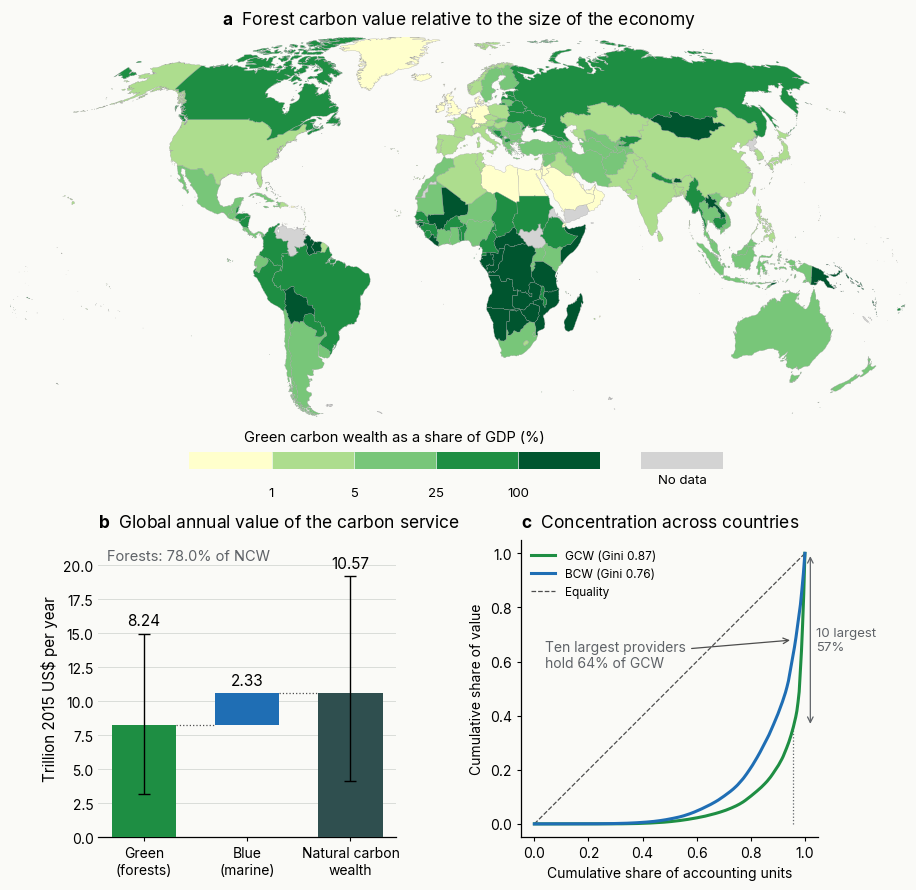

In [5]:
fig = plt.figure(figsize=(14, 10.4), facecolor=BG)
grid = fig.add_gridspec(2, 2, height_ratios=[1.30, 1], hspace=0.34, wspace=0.26)

# (a) carte GCW / PIB
ax = fig.add_subplot(grid[0, :])
ax.set_facecolor(BG)
class_map(ax, base.set_index("iso3")["gcw_share_of_gdp"],
          bins=[-np.inf, 1, 5, 25, 100, np.inf], ticks=["1", "5", "25", "100"],
          colors=FOREST_COLS, legend_title="Green carbon wealth as a share of GDP (%)")
panel(ax, "a", "Forest carbon value relative to the size of the economy", loc="center")

# (b) cascade GCW -> BCW -> NCW
ax = fig.add_subplot(grid[1, 0])
clean(ax, spines=("bottom"))
ax.set_box_aspect(1)
ax.set_anchor("E")          # les deux carrés se rapprochent du centre de la figure
g, b, n =(np.nansum(d, axis=0) / 1e12 for d in (D_GCW, D_BCW, D_NCW))
means = [g.mean(), b.mean(), n.mean()]
lo = [np.percentile(v, 5) for v in (g, b, n)]
hi = [np.percentile(v, 95) for v in (g, b, n)]
xs = np.arange(3)
ax.bar(xs[0], means[0], 0.62, color=GREEN, zorder=3)
ax.bar(xs[1], means[1], 0.62, bottom=means[0], color=BLUE, zorder=3)
ax.bar(xs[2], means[2], 0.62, color="#2f4f4f", zorder=3)
ax.plot([0.31, 0.69], [means[0]] * 2, color=MUTED, lw=0.9, ls=":", zorder=4)
ax.plot([1.31, 1.69], [means[2]] * 2, color=MUTED, lw=0.9, ls=":", zorder=4)
for i, (m, l, h) in enumerate(zip(means, lo, hi)):
    if i == 1:
        # le bleu est une marche posée sur le vert : sa valeur s'écrit au-dessus de la marche
        label_y = means[0] + m
    else:
        ax.errorbar(xs[i], m, yerr=[[m - l], [h - m]], fmt="none", ecolor=TEXT,
                    elinewidth=1.0, capsize=4, zorder=5)
        label_y = h                      # au-dessus de la moustache, jamais à travers
    ax.text(xs[i], label_y + max(hi) * 0.02, f"{m:.2f}", ha="center", va="bottom", fontsize=11,
            fontweight="bold", color=TEXT)
ax.set_xticks(xs)
ax.tick_params(axis="y", which="both", length=0)
ax.set_xticklabels(["Green\n(forests)", "Blue\n(marine)", "Natural carbon\nwealth"], fontsize=10)
ax.set_ylabel("Trillion 2015 US\$ per year", fontsize=11)
ax.set_ylim(0, max(hi) * 1.14)
ax.text(0.03, 0.97, f"Forests: {100 * means[0] / means[2]:.1f}% of NCW", transform=ax.transAxes,
        fontsize=10.5, va="top", color=TEXT2)
panel(ax, "b", "Global annual value of the carbon service")

# (c) Lorenz
ax = fig.add_subplot(grid[1, 1])
clean(ax, grid_axis=None, spines=("left", "bottom"))
ax.set_box_aspect(1)
ax.set_anchor("W")


def lorenz(values):
    v = np.sort(np.asarray(values, dtype="float64"))
    v = v[~np.isnan(v)]
    return np.linspace(0, 1, v.size + 1), np.concatenate([[0], np.cumsum(v) / v.sum()])


def gini(values):
    v = np.sort(np.asarray(values, dtype="float64"))
    v = v[~np.isnan(v)]
    k = v.size
    return float((2 * np.arange(1, k + 1) - k - 1) @ v / (k * v.sum()))



for col, color, label in [("gcw_usd2015_yr_mean", GREEN, "GCW"),
                          ("bcw_usd2015_yr_mean", BLUE, "BCW")]:
    x, y = lorenz(base[col])
    ax.plot(x, y, color=color, lw=2.2, label=f"{label} (Gini {gini(base[col]):.2f})", zorder=3)
ax.plot([0, 1], [0, 1], color=MUTED, ls="--", lw=0.9, label="Equality", zorder=2)
top10 = base.nlargest(10, "gcw_usd2015_yr_mean")["gcw_usd2015_yr_mean"].sum() / base["gcw_usd2015_yr_mean"].sum()
ax.annotate(f"Ten largest providers\nhold {100 * top10:.0f}% of GCW", xy=(0.955, 1 - top10 / 2),
            xytext=(0.04, 0.58), fontsize=10, color=TEXT2,
            arrowprops=dict(arrowstyle="->", color=MUTED, lw=0.9))
ax.set_xlabel("Cumulative share of accounting units", fontsize=10)
ax.set_ylabel("Cumulative share of value", fontsize=10)
ax.legend(frameon=False, loc="upper left", fontsize=8.5)
x_cut = 1 - 10 / base["gcw_usd2015_yr_mean"].notna().sum()   # ≈ 0,96
y_cut = 1 - top10                                            # ≈ 0,43
ax.plot([x_cut, x_cut], [0, y_cut], color=TEXT2, ls=":", lw=0.9)
ax.annotate("", xy=(1.02, 1.0), xytext=(1.02, y_cut),
            arrowprops=dict(arrowstyle="<->", color=TEXT2, lw=0.9), annotation_clip=False)
ax.text(1.04, (1 + y_cut) / 2, "10 largest\n57%", va="center", fontsize=9.5,
        color=TEXT2, transform=ax.transData, clip_on=False)
panel(ax, "c", "Concentration across countries")

save(fig, "Figure1_service_scale_and_concentration")
plt.show()

## Figure 2 - Composition des comptes et comparaison des flux comptabilisés

- **a** carte de la part forestière dans le NCW ;
- **b** émissions comparées aux ajouts bruts forestiers dans la biomasse vivante et au flux bleu comptabilisé ;
- **c** solde comptable des flux retenus moins émissions, qui n’est pas un bilan net du carbone de l’écosystème forestier.

[saved] Figure2_blue_carbon_composition_and_balance.png / Figure2_blue_carbon_composition_and_balance.pdf


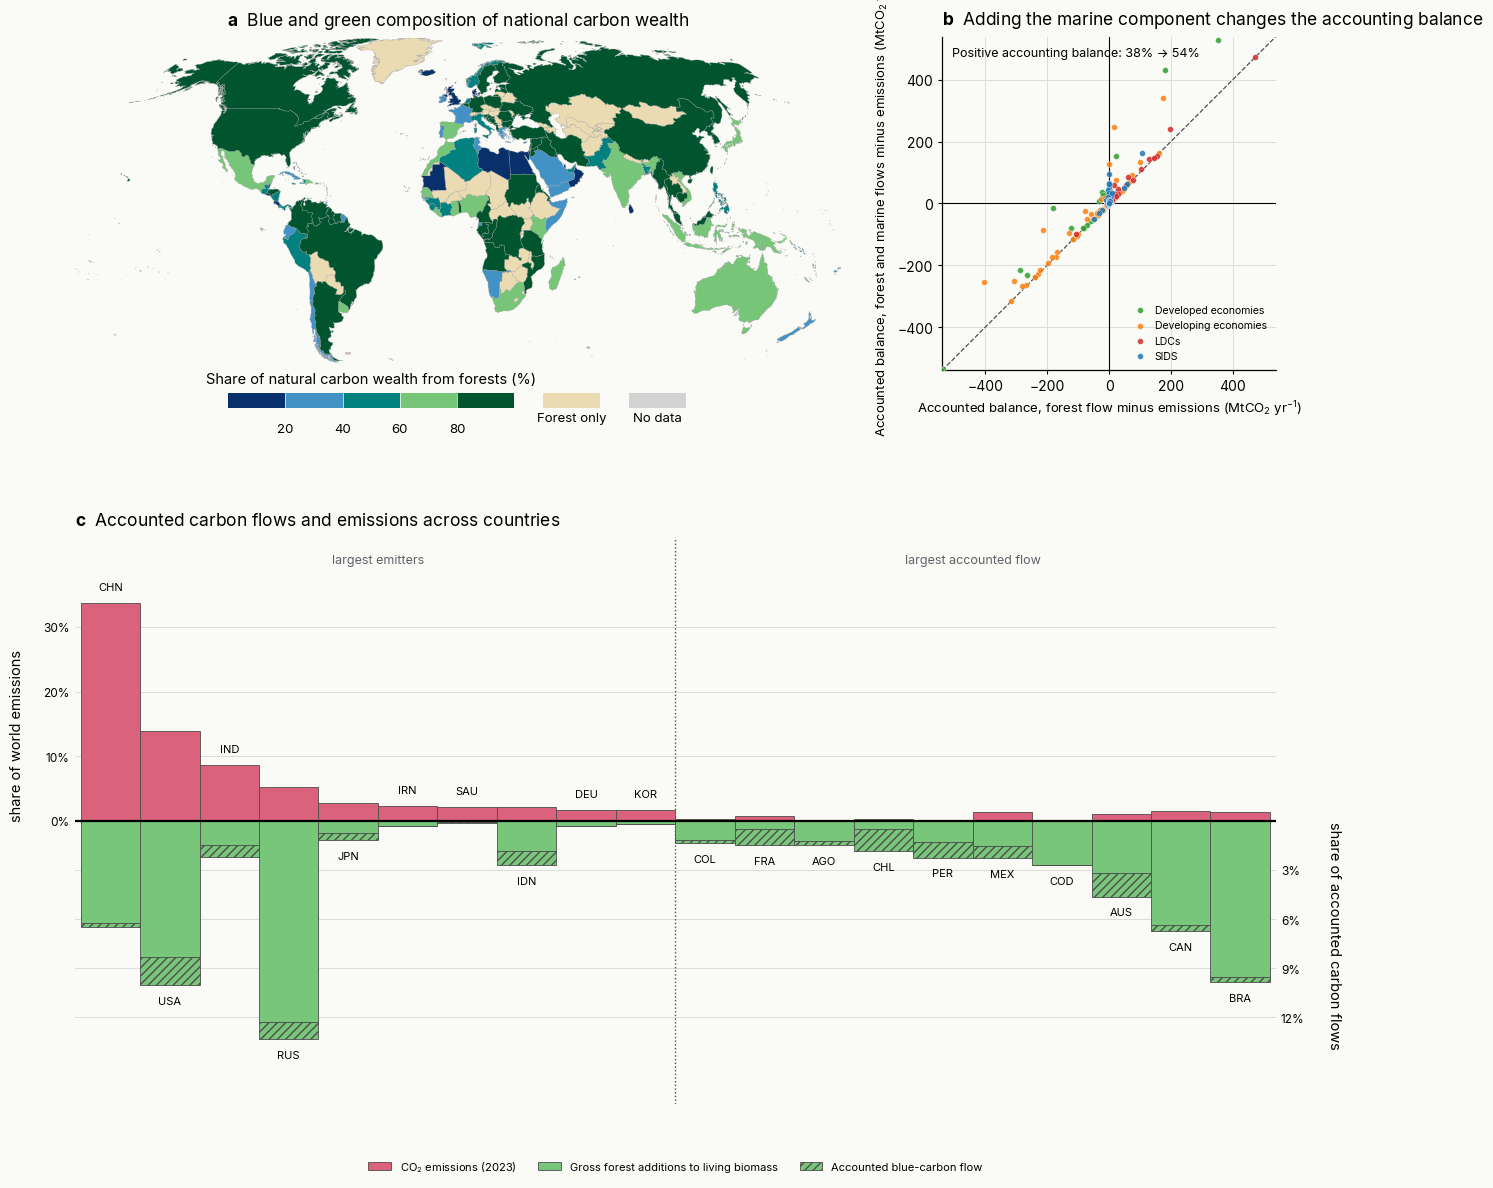

In [6]:
GREEN_BLUE = LinearSegmentedColormap.from_list("gb", [OCEAN_COLS[4], OCEAN_COLS[2], "#008080",
                                                      FOREST_COLS[2], FOREST_COLS[4]])
COMP_COLORS = [GREEN_BLUE(t) for t in np.linspace(0, 1, 5)]

seq_gcw = D_GCW / GSCC
seq_ncw = D_NCW / GSCC
emis = base.set_index("iso3")["emissions_tco2"].reindex(UNITS).to_numpy()
bal_gcw, bal_ncw = seq_gcw.mean(axis=1) - emis, seq_ncw.mean(axis=1) - emis
balance = (pd.DataFrame({"iso3": UNITS, "bal_gcw": bal_gcw, "bal_ncw": bal_ncw})
           .dropna().merge(base[["iso3", "groups", "seq_gcw_tco2", "seq_bcw_tco2", "emissions_tco2"]]
                           if "seq_gcw_tco2" in base.columns else base[["iso3", "groups"]], on="iso3"))
sink_before = 100 * (balance["bal_gcw"] > 0).mean()
sink_after = 100 * (balance["bal_ncw"] > 0).mean()

fig = plt.figure(figsize=(15.5, 14), facecolor=BG)
grid = fig.add_gridspec(2, 3, height_ratios=[1.25, 2], hspace=0.34, wspace=0.30)

# (a) carte de composition
ax = fig.add_subplot(grid[0, 0:2])
ax.set_facecolor(BG)
class_map(ax, base.set_index("iso3")["forest_share"],
          bins=[-np.inf, 20, 40, 60, 80, np.inf], ticks=["20", "40", "60", "80"],
          colors=COMP_COLORS, legend_title="Share of natural carbon wealth from forests (%)",
          extra_cats=[(base.set_index("iso3")["has_gcw"] & ~base.set_index("iso3")["has_bcw"],
                       "Forest only", "#eadbb3")])
panel(ax, "a", "Blue and green composition of national carbon wealth", loc="center")

# (c) émissions vers le haut, séquestration vers le bas - bande basse, pleine largeur
ax = fig.add_subplot(grid[1, :])
clean(ax, grid_axis=None)

panel_src = base.dropna(subset=["emissions_tco2", "population"]).copy()
panel_src["seq_gcw"] = (pd.Series(seq_gcw.mean(axis=1), index=UNITS)
                        .reindex(panel_src["iso3"]).to_numpy())
panel_src["seq_bcw"] = (pd.Series((D_BCW / GSCC).mean(axis=1), index=UNITS)
                        .reindex(panel_src["iso3"]).to_numpy())
panel_src = panel_src.dropna(subset=["seq_gcw", "seq_bcw"])
panel_src["seq_total"] = panel_src["seq_gcw"] + panel_src["seq_bcw"]
left = panel_src.nlargest(10, "emissions_tco2").sort_values("emissions_tco2", ascending=False)
right = (panel_src[~panel_src["iso3"].isin(left["iso3"])].nlargest(10, "seq_total")
         .sort_values("seq_total"))
pan = pd.concat([left, right], ignore_index=True)

world_emis, world_seq = panel_src["emissions_tco2"].sum(), panel_src["seq_total"].sum()
e = 100 * pan["emissions_tco2"].to_numpy() / world_emis
g_ = 100 * pan["seq_gcw"].to_numpy() / world_seq
b_ = 100 * pan["seq_bcw"].to_numpy() / world_seq
k = e.max() / (g_ + b_).max()
x = np.arange(len(pan))
bar = dict(width=1.0, edgecolor="#4d4d4d", linewidth=0.6, zorder=3)
ax.bar(x, e, color=PINK, label="CO$_2$ emissions (2023)", **bar)
ax.bar(x, -g_ * k, color=FOREST_COLS[2], label="Gross forest additions to living biomass", **bar)
ax.bar(x, -b_ * k, bottom=-g_ * k, color=FOREST_COLS[2], hatch="////", label="Accounted blue-carbon flow", **bar)
span = max(e.max(), ((g_ + b_) * k).max())
ax.set_ylim(-span * 1.30, span * 1.30)
ax.axhline(0, color="black", lw=1.6, zorder=8)
for xi, iso, ei, si in zip(x, pan["iso3"], e, (g_ + b_) * k):
    if ei >= si:
        ax.text(xi, ei + span * 0.05, iso, ha="center", va="bottom", fontsize=8, color=TEXT)
    else:
        ax.text(xi, -si - span * 0.05, iso, ha="center", va="top", fontsize=8, color=TEXT)
up_ticks = np.arange(0, span + 1, 10)
ax.set_yticks(up_ticks)
ax.set_yticklabels([f"{v:.0f}%" for v in up_ticks], fontsize=8.5)
ax2 = ax.twinx()
ax2.set_ylim(ax.get_ylim())
down_ticks = np.arange(3, span / k, 3)
ax2.set_yticks(-down_ticks * k)
ax2.set_yticklabels([f"{v:.0f}%" for v in down_ticks], fontsize=8.5)
for a in (ax, ax2):
    for spine in a.spines.values():
        spine.set_visible(False)
    a.tick_params(length=0, colors=TEXT)
ax2.set_facecolor("none")
for y in np.concatenate([up_ticks[1:], -down_ticks * k]):
    ax.axhline(y, color=GRID, lw=0.7, zorder=0)
ax.set_xticks([])
ax.set_xlim(-0.6, len(pan) - 0.4)
ax.axvline(9.5, color=MUTED, ls=":", lw=1.0)
ax.text(4.5, span * 1.18, "largest emitters", ha="center", fontsize=9, color=TEXT2)
ax.text(14.5, span * 1.18, "largest accounted flow", ha="center", fontsize=9, color=TEXT2)
# intitulés accrochés à la ligne zéro : émissions de 0 vers le haut à gauche,
# séquestration de 0 vers le bas à droite (texte placé à la main, pas via set_ylabel)
zero_frac = (0 - ax.get_ylim()[0]) / (ax.get_ylim()[1] - ax.get_ylim()[0])
ax.text(-0.048, zero_frac, "share of world emissions", transform=ax.transAxes, rotation=90,
        ha="center", va="bottom", fontsize=10.5, color=TEXT)
ax.text(1.048, zero_frac, "share of accounted carbon flows", transform=ax.transAxes, rotation=270,
        ha="center", va="top", fontsize=10.5, color=TEXT)
ax.legend(frameon=False, fontsize=8, ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.14))
panel(ax, "c", "Accounted carbon flows and emissions across countries")

# (b) bilan net, forêt seule contre forêt + océan
ax_bal = fig.add_subplot(grid[0, 2])
ax = ax_bal
clean(ax, grid_axis="both", spines=("left", "bottom"))
ax.set_box_aspect(1)
for g_name, d in balance.groupby("groups"):
    ax.scatter(d["bal_gcw"] / 1e6, d["bal_ncw"] / 1e6, s=18, alpha=0.85, zorder=3,
               color=GROUP_COLORS.get(g_name, "grey"), label=g_name, edgecolor="white", linewidth=0.3)
lim = np.nanpercentile(np.abs(balance[["bal_gcw", "bal_ncw"]].to_numpy()) / 1e6, 96)
ax.plot([-lim, lim], [-lim, lim], color=MUTED, ls="--", lw=0.9, zorder=2)
ax.axhline(0, color=TEXT, lw=0.8, zorder=2)
ax.axvline(0, color=TEXT, lw=0.8, zorder=2)
ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)
ax.set_xlabel("Accounted balance, forest flow minus emissions (MtCO$_2$ yr$^{-1}$)", fontsize=9.5)
ax.set_ylabel("Accounted balance, forest and marine flows minus emissions (MtCO$_2$ yr$^{-1}$)", fontsize=9.5)
ax.text(0.03, 0.97, f"Positive accounting balance: {sink_before:.0f}% → {sink_after:.0f}%", transform=ax.transAxes,
        fontsize=9, va="top", color=TEXT)
ax.legend(frameon=False, fontsize=7.5, loc="lower right", handletextpad=0.4)
panel(ax, "b", "Adding the marine component changes the accounting balance")

save(fig, "Figure2_blue_carbon_composition_and_balance")
plt.show()

## Figure 3 - Déforestation déclarée et capacité annuelle d’ajout brut associée

- **a** carte de l'intensité d'érosion, avec les non-déclarants en gris et les déclarations nulles distinguées ;
- **b** typologie service contre érosion, quatre cases ;
- **c** déforestation déclarée par intervalle depuis 1990 et capacité cumulée détruite.

<>:48: SyntaxWarning: invalid escape sequence '\$'
<>:48: SyntaxWarning: invalid escape sequence '\$'
<temporary-folder>\ipykernel_13556\1802271810.py:48: SyntaxWarning: invalid escape sequence '\$'
  ax.set_xlabel("Green carbon wealth (billion 2015 US\$ per year)", fontsize=9.5)


[saved] Figure3_erosion_of_the_service.png / Figure3_erosion_of_the_service.pdf


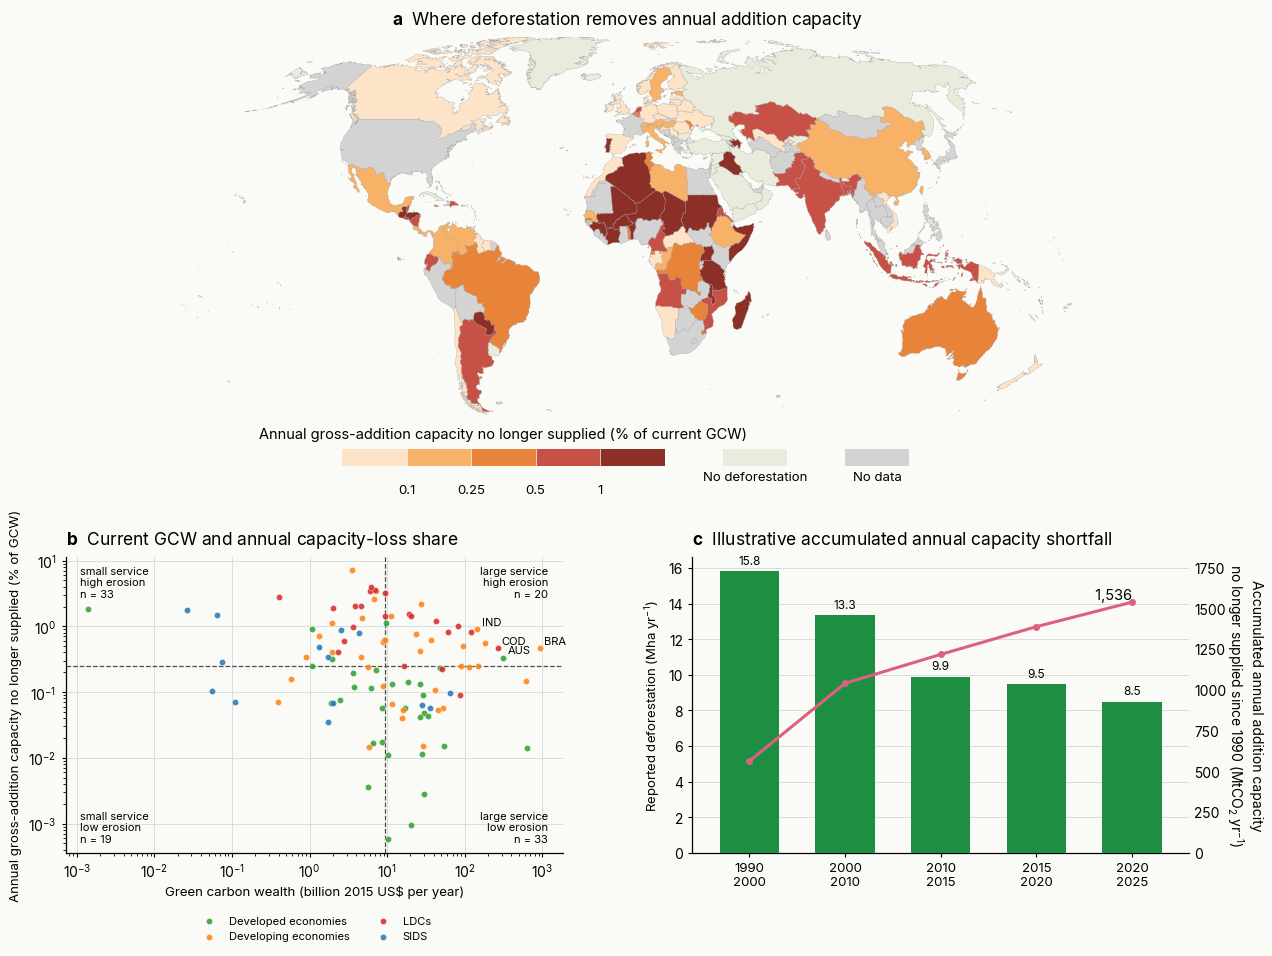

In [7]:
EROSION_COLS = ["#fde3c8", "#f7b267", "#e8833a", "#c75146", "#8c2f26"]

fig = plt.figure(figsize=(14.5, 10.6), facecolor=BG)
grid = fig.add_gridspec(2, 2, height_ratios=[1.30, 1], hspace=0.40, wspace=0.26)

# (a) carte de l'intensité d'érosion
ax = fig.add_subplot(grid[0, :])
ax.set_facecolor(BG)
zero_mask = base.set_index("iso3").apply(
    lambda r: bool(r["reported"]) and (r["erosion_pct"] == 0 or pd.isna(r["erosion_pct"])), axis=1)
class_map(ax, base.set_index("iso3")["erosion_pct"].replace(0, np.nan),
          bins=[0, 0.1, 0.25, 0.5, 1.0, np.inf], ticks=["0.1", "0.25", "0.5", "1"],
          colors=EROSION_COLS,
          legend_title="Annual gross-addition capacity no longer supplied (% of current GCW)",
          extra_cats=[(zero_mask, "No deforestation", "#e9ecdc")],
          legend_box=(0.18, -0.16, 0.64, 0.13), legend_gap=0.9)
panel(ax, "a", "Where deforestation removes annual addition capacity", loc="center")

# (b) typologie service x érosion
ax = fig.add_subplot(grid[1, 0])
clean(ax, grid_axis="both", spines=("left", "bottom"))
t = base.dropna(subset=["gcw_usd2015_yr_mean", "erosion_pct"]).query(
    "gcw_usd2015_yr_mean > 0 and erosion_pct > 0")
med_g, med_e = t["gcw_usd2015_yr_mean"].median(), t["erosion_pct"].median()
for g_name, d in t.groupby("groups"):
    ax.scatter(d["gcw_usd2015_yr_mean"] / 1e9, d["erosion_pct"], s=20, alpha=0.85, zorder=3,
               color=GROUP_COLORS.get(g_name, "grey"), label=g_name, edgecolor="white", linewidth=0.3)
for _, row in t.nlargest(4, "loss_usd").iterrows():
    ax.annotate(row["iso3"], (row["gcw_usd2015_yr_mean"] / 1e9, row["erosion_pct"]),
                fontsize=8, color=TEXT, xytext=(3, 3), textcoords="offset points")
ax.axvline(med_g / 1e9, color=MUTED, ls="--", lw=0.9, zorder=2)
ax.axhline(med_e, color=MUTED, ls="--", lw=0.9, zorder=2)
ax.set_xscale("log")
ax.set_yscale("log")
counts = {
    "large service\nlow erosion": ((t["gcw_usd2015_yr_mean"] >= med_g) & (t["erosion_pct"] < med_e)).sum(),
    "large service\nhigh erosion": ((t["gcw_usd2015_yr_mean"] >= med_g) & (t["erosion_pct"] >= med_e)).sum(),
    "small service\nlow erosion": ((t["gcw_usd2015_yr_mean"] < med_g) & (t["erosion_pct"] < med_e)).sum(),
    "small service\nhigh erosion": ((t["gcw_usd2015_yr_mean"] < med_g) & (t["erosion_pct"] >= med_e)).sum(),
}
corners = {"large service\nlow erosion": (0.97, 0.03, "right", "bottom"),
           "large service\nhigh erosion": (0.97, 0.97, "right", "top"),
           "small service\nlow erosion": (0.03, 0.03, "left", "bottom"),
           "small service\nhigh erosion": (0.03, 0.97, "left", "top")}
for key, (fx, fy, ha, va) in corners.items():
    ax.text(fx, fy, f"{key}\nn = {counts[key]}", transform=ax.transAxes, fontsize=8,
            ha=ha, va=va, color=TEXT)
ax.set_xlabel("Green carbon wealth (billion 2015 US\$ per year)", fontsize=9.5)
ax.set_ylabel("Annual gross-addition capacity no longer supplied (% of GCW)", fontsize=9.5)
ax.legend(frameon=False, fontsize=8, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.18))
panel(ax, "b", "Current GCW and annual capacity-loss share")

# (c) déforestation par intervalle et capacité cumulée détruite
ax = fig.add_subplot(grid[1, 1])
clean(ax, spines=("left", "bottom"))
series = defor[INTERVALS].sum() / 1000
ax.bar(np.arange(len(series)), series.values, 0.62, color=FOREST_COLS[3], zorder=3)
ax.set_xticks(np.arange(len(series)))
ax.set_xticklabels([s.replace("-", "\n") for s in series.index], fontsize=9.5, rotation=0)
ax.set_ylabel("Reported deforestation (Mha yr$^{-1}$)", fontsize=9.5)
for i, v in enumerate(series.values):
    ax.text(i, v + 0.25, f"{v:.1f}", ha="center", va="bottom", fontsize=8.5, color=TEXT)
# scénario cumulé : suppose que les surfaces déboisées restent hors forêt et que les taux moyens actuels s’appliquent
rate_per_ha = shares.to_numpy() @ rates.loc[list(shares.columns), "rate_tc_ha_yr_mean"].to_numpy()
rate_per_ha = pd.Series(rate_per_ha, index=shares.index)
YEARS_PER_INTERVAL = {"1990-2000": 10, "2000-2010": 10, "2010-2015": 5, "2015-2020": 5, "2020-2025": 5}
interval_loss = {}
for interval, n_years in YEARS_PER_INTERVAL.items():
    area_ha = (defor.set_index("iso3")[interval] * 1000).reindex(rate_per_ha.index)
    interval_loss[interval] = float(np.nansum(area_ha * rate_per_ha) * n_years * CO2_PER_C / 1e6)
cumulative = np.cumsum(list(interval_loss.values()))

ax2 = ax.twinx()
ax2.set_facecolor("none")
ax2.plot(np.arange(len(series)), cumulative, color=PINK, lw=2.2, marker="o", ms=4, zorder=4)
ax2.set_ylabel("Accumulated annual addition capacity\nno longer supplied since 1990 (MtCO$_2$ yr$^{-1}$)", fontsize=10,
               rotation=270, labelpad=26, color=TEXT)
ax2.tick_params(length=0, colors=TEXT, labelsize=10)
ax2.set_ylim(0, cumulative[-1] * 1.18)
for spine in ax2.spines.values():
    spine.set_visible(False)
ax2.text(len(series) - 1, cumulative[-1], f"  {cumulative[-1]:,.0f}", color=TEXT, fontsize=10.5,
         fontweight="bold", va="bottom", ha="right")
ax.set_xlim(-0.6, len(series) - 0.4)
panel(ax, "c", "Illustrative accumulated annual capacity shortfall")

save(fig, "Figure3_erosion_of_the_service")
plt.show()

## Figure 4 - Celui qui perd le puits n'est pas celui qui peut payer

- **a** coût annuel par groupe, allocation domestique contre effort partagé au prorata du PIB ;
- **b** charge domestique rapportée au PIB, quinze premiers pays ;
- **c** échelle : perte forestière observée contre scénarios d'affaiblissement du puits océanique.

<>:27: SyntaxWarning: invalid escape sequence '\$'
<>:27: SyntaxWarning: invalid escape sequence '\$'
<>:27: SyntaxWarning: invalid escape sequence '\$'
<>:27: SyntaxWarning: invalid escape sequence '\$'
<temporary-folder>\ipykernel_13556\3309585060.py:27: SyntaxWarning: invalid escape sequence '\$'
  ax.set_ylabel(f"Annual cost at US\${PRICE:.0f} per tCO$_2$\n(billion 2015 US\$)", fontsize=9.5)
<temporary-folder>\ipykernel_13556\3309585060.py:27: SyntaxWarning: invalid escape sequence '\$'
  ax.set_ylabel(f"Annual cost at US\${PRICE:.0f} per tCO$_2$\n(billion 2015 US\$)", fontsize=9.5)


[saved] Figure4_compensation_burden.png / Figure4_compensation_burden.pdf


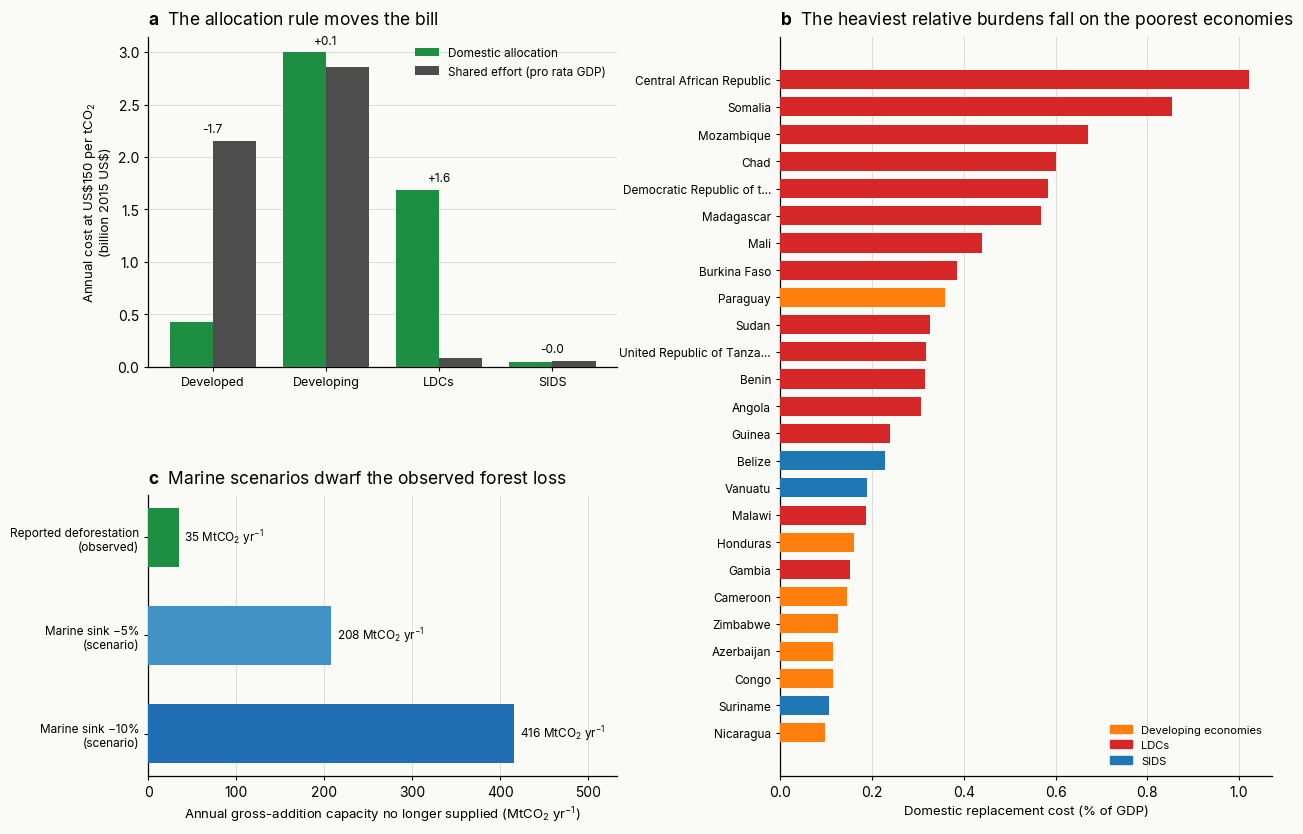

In [8]:
PRICE = 150.0   # TODO : remplacer par un prix de scénario AR6 converti en dollars 2015

comp = base.dropna(subset=["loss_tco2", "gdp"]).copy()
comp["cost_domestic"] = comp["loss_tco2"] * PRICE
comp["cost_shared"] = comp["cost_domestic"].sum() * comp["gdp"] / comp["gdp"].sum()
comp["burden_pct_gdp"] = 100 * comp["cost_domestic"] / comp["gdp"]

fig = plt.figure(figsize=(14.5, 9.6), facecolor=BG)
grid = fig.add_gridspec(2, 2, width_ratios=[1, 1.05], height_ratios=[1, 0.85], hspace=0.42, wspace=0.34)

# (a) coût par groupe sous deux règles
ax = fig.add_subplot(grid[0, 0])
clean(ax, spines=("left", "bottom"))
by_group = comp.groupby("groups")[["cost_domestic", "cost_shared"]].sum().reindex(GROUP_ORDER).dropna()
idx = np.arange(len(by_group))
ax.bar(idx - 0.19, by_group["cost_domestic"] / 1e9, 0.38, color=FOREST_COLS[3],
       label="Domestic allocation", zorder=3)
ax.bar(idx + 0.19, by_group["cost_shared"] / 1e9, 0.38, color=MUTED,
       label="Shared effort (pro rata GDP)", zorder=3)
for i, row in enumerate(by_group.itertuples()):
    delta = (row.cost_domestic - row.cost_shared) / 1e9
    ax.annotate(f"{delta:+.1f}", (i, max(row.cost_domestic, row.cost_shared) / 1e9),
                textcoords="offset points", xytext=(0, 6), ha="center", fontsize=8.5,
                color=TEXT)
ax.set_xticks(idx)
ax.set_xticklabels([g.replace(" economies", "") for g in by_group.index], fontsize=9)
ax.set_ylabel(f"Annual cost at US\${PRICE:.0f} per tCO$_2$\n(billion 2015 US\$)", fontsize=9.5)
ax.legend(frameon=False, fontsize=8.5)
panel(ax, "a", "The allocation rule moves the bill")

# (b) charge rapportée au PIB
ax = fig.add_subplot(grid[:, 1])
clean(ax, grid_axis="x", spines=("left", "bottom"))
top = comp.nlargest(25, "burden_pct_gdp").sort_values("burden_pct_gdp")
ax.barh(np.arange(len(top)), top["burden_pct_gdp"], 0.7, zorder=3,
        color=[GROUP_COLORS.get(g, "grey") for g in top["groups"]])
ax.set_yticks(np.arange(len(top)))
ax.set_yticklabels([n if len(n) <= 26 else n[:24] + "…" for n in top["name"]], fontsize=8.5)
ax.set_xlabel("Domestic replacement cost (% of GDP)", fontsize=9.5)
present = [g for g in GROUP_ORDER if g in set(top["groups"])]
ax.legend(handles=[Patch(color=GROUP_COLORS[g], label=g) for g in present],
          frameon=False, fontsize=8, loc="lower right")
panel(ax, "b", "The heaviest relative burdens fall on the poorest economies")

# (c) échelle : forêt observée contre scénarios océan
ax = fig.add_subplot(grid[1, 0])
clean(ax, grid_axis="x", spines=("left", "bottom"))
ocean_tco2 = (np.nansum(D_BCW, axis=0) / GSCC).mean()
rows = [("Reported deforestation\n(observed)", np.nansum(loss_tco2[reported], axis=0).mean() / 1e6, FOREST_COLS[3]),
        ("Marine sink −5%\n(scenario)", 0.05 * ocean_tco2 / 1e6, OCEAN_COLS[2]),
        ("Marine sink −10%\n(scenario)", 0.10 * ocean_tco2 / 1e6, OCEAN_COLS[3])]
ypos = np.arange(len(rows))
ax.barh(ypos, [r[1] for r in rows], 0.6, color=[r[2] for r in rows], zorder=3)
for y, (_, v, _) in zip(ypos, rows):
    ax.text(v + 6, y, f"{v:,.0f} MtCO$_2$ yr$^{{-1}}$", va="center", fontsize=8.5, color=TEXT)
ax.set_yticks(ypos)
ax.set_yticklabels([r[0] for r in rows], fontsize=8.5)
ax.invert_yaxis()
ax.set_xlabel("Annual gross-addition capacity no longer supplied (MtCO$_2$ yr$^{-1}$)", fontsize=9.5)
ax.set_xlim(0, max(r[1] for r in rows) * 1.28)
panel(ax, "c", "Marine scenarios dwarf the observed forest loss")

save(fig, "Figure4_compensation_burden")
plt.show()

## Annexe - les figures actuelles du manuscrit, restylées

Reprise des quatre figures produites par `code/scripts/build_manuscript_artifacts.py`, avec la même charte que
ci-dessus : fond crème, texte noir, couleurs de groupes `tab:`, spines gauche et bas, grille légère.
Elles restent des figures à un ou deux panneaux ; elles servent de comparaison avec les versions à trois panneaux.

[saved] Annex1_service_and_concentration.png / Annex1_service_and_concentration.pdf


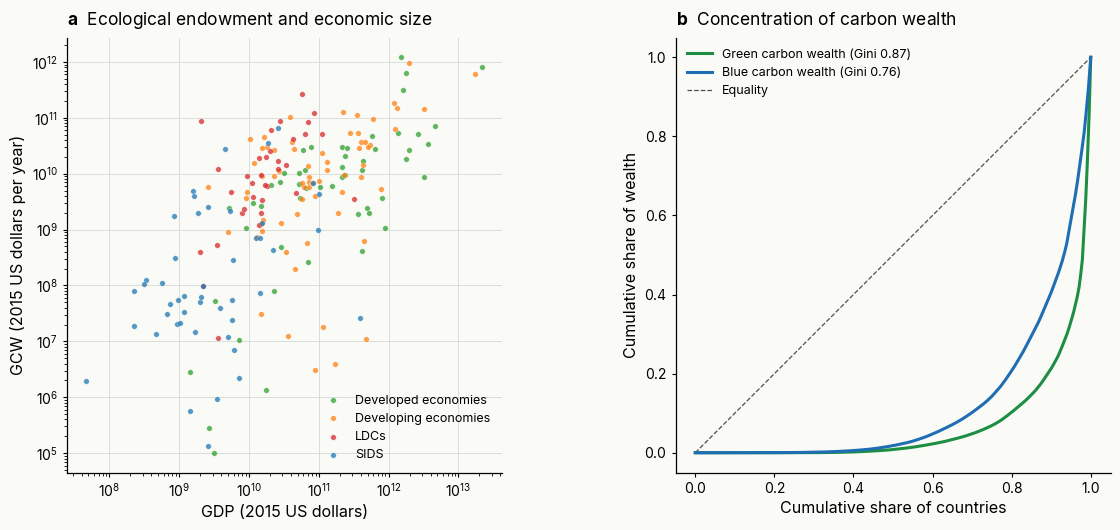

In [9]:
# A1 - dotation écologique et taille économique, puis concentration
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.4), facecolor=BG)
scatter = base.dropna(subset=["gdp", "gcw_usd2015_yr_mean"]).query("gdp > 0 and gcw_usd2015_yr_mean > 0")
ax = axes[0]
clean(ax, grid_axis="both", spines=("left", "bottom"))
ax.set_box_aspect(1)
for g_name, d in scatter.groupby("groups"):
    ax.scatter(d["gdp"], d["gcw_usd2015_yr_mean"], s=16, alpha=0.75, label=g_name,
               color=GROUP_COLORS.get(g_name, "grey"), edgecolor="white", linewidth=0.3, zorder=3)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("GDP (2015 US dollars)")
ax.set_ylabel("GCW (2015 US dollars per year)")
ax.legend(frameon=False, fontsize=9, loc="lower right")
panel(ax, "a", "Ecological endowment and economic size")

ax = axes[1]
clean(ax, grid_axis=None, spines=("left", "bottom"))
ax.set_box_aspect(1)
for col, color, label in [("gcw_usd2015_yr_mean", GREEN, "Green carbon wealth"),
                          ("bcw_usd2015_yr_mean", BLUE, "Blue carbon wealth")]:
    x, y = lorenz(base[col])
    ax.plot(x, y, color=color, lw=2.2, label=f"{label} (Gini {gini(base[col]):.2f})", zorder=3)
ax.plot([0, 1], [0, 1], color=MUTED, ls="--", lw=0.9, label="Equality", zorder=2)
ax.set_xlabel("Cumulative share of countries")
ax.set_ylabel("Cumulative share of wealth")
ax.legend(frameon=False, fontsize=9, loc="upper left")
panel(ax, "b", "Concentration of carbon wealth")
fig.tight_layout()
save(fig, "Annex1_service_and_concentration")
plt.show()

[saved] Annex2_composition_and_flux.png / Annex2_composition_and_flux.pdf


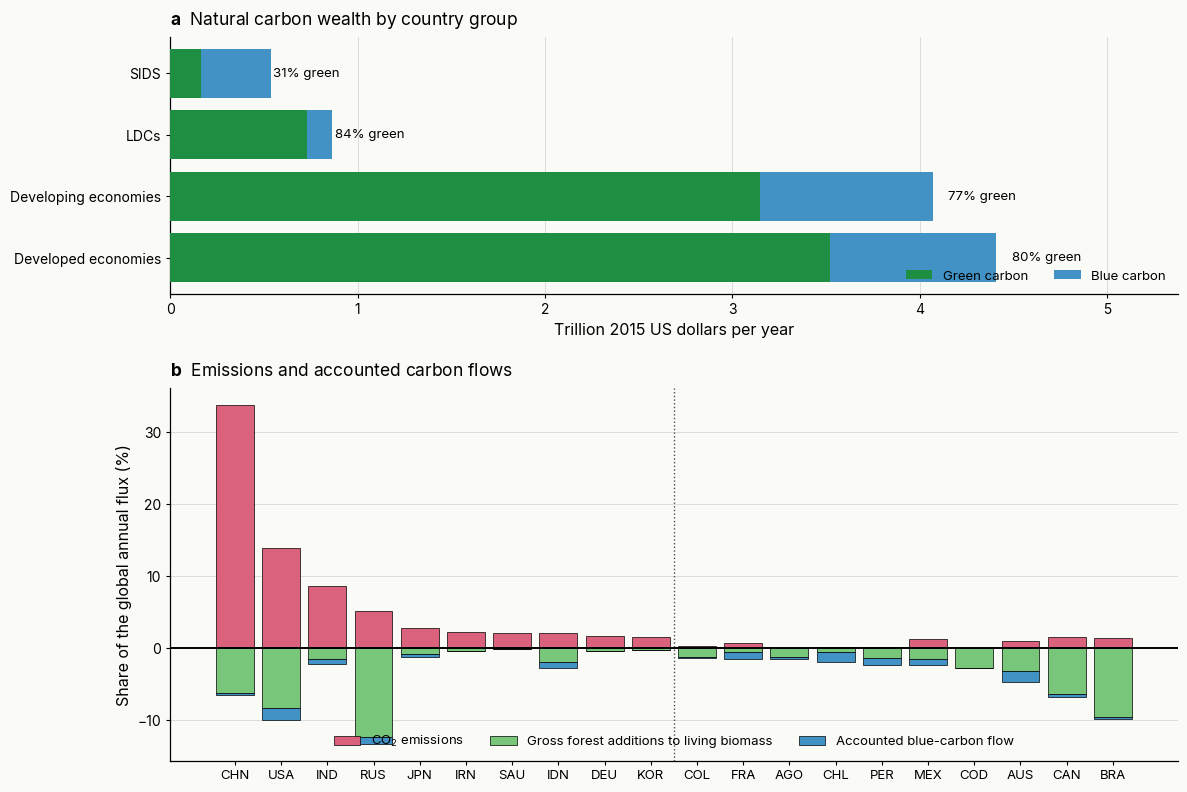

In [10]:
# A2 - composition par groupe, puis émetteurs et puits
fig = plt.figure(figsize=(13, 9.4), facecolor=BG)
grid = fig.add_gridspec(2, 1, height_ratios=[1, 1.45], hspace=0.30)

ax = fig.add_subplot(grid[0])
clean(ax, grid_axis="x", spines=("left", "bottom"))
comp_group = (base.dropna(subset=["forest_share"])
              .groupby("groups")[["gcw_usd2015_yr_mean", "bcw_usd2015_yr_mean"]].sum()
              .reindex(GROUP_ORDER).dropna() / 1e12)
ax.barh(comp_group.index, comp_group["gcw_usd2015_yr_mean"], color=FOREST_COLS[3],
        label="Green carbon", zorder=3)
ax.barh(comp_group.index, comp_group["bcw_usd2015_yr_mean"], left=comp_group["gcw_usd2015_yr_mean"],
        color=OCEAN_COLS[2], label="Blue carbon", zorder=3)
for y, (g_val, b_val) in enumerate(zip(comp_group["gcw_usd2015_yr_mean"], comp_group["bcw_usd2015_yr_mean"])):
    total = g_val + b_val
    ax.text(total * 1.02, y, f"{100 * g_val / total:.0f}% green", va="center", fontsize=9.5, color=TEXT)
ax.set_xlabel("Trillion 2015 US dollars per year")
ax.set_xlim(0, comp_group.sum(axis=1).max() * 1.22)
ax.legend(frameon=False, ncol=2, fontsize=9.5, loc="lower right")
panel(ax, "a", "Natural carbon wealth by country group")

ax = fig.add_subplot(grid[1])
clean(ax, grid_axis="y", spines=("left", "bottom"))
x = np.arange(len(pan))
ax.bar(x, e, width=0.82, color=PINK, label="CO$_2$ emissions", edgecolor="black", linewidth=0.5, zorder=3)
ax.bar(x, -g_, width=0.82, color=FOREST_COLS[2], label="Gross forest additions to living biomass",
       edgecolor="black", linewidth=0.5, zorder=3)
ax.bar(x, -b_, bottom=-g_, width=0.82, color=OCEAN_COLS[2], label="Accounted blue-carbon flow",
       edgecolor="black", linewidth=0.5, zorder=3)
ax.axhline(0, color="black", lw=1.4, zorder=8)
ax.axvline(9.5, color=MUTED, ls=":", lw=1.0)
ax.set_xticks(x)
ax.set_xticklabels(pan["iso3"], fontsize=9.5)
ax.set_ylabel("Share of the global annual flux (%)")
ax.legend(frameon=False, ncol=3, fontsize=9.5, loc="lower center")
panel(ax, "b", "Emissions and accounted carbon flows")
save(fig, "Annex2_composition_and_flux")
plt.show()

[saved] Annex3_service_and_erosion.png / Annex3_service_and_erosion.pdf


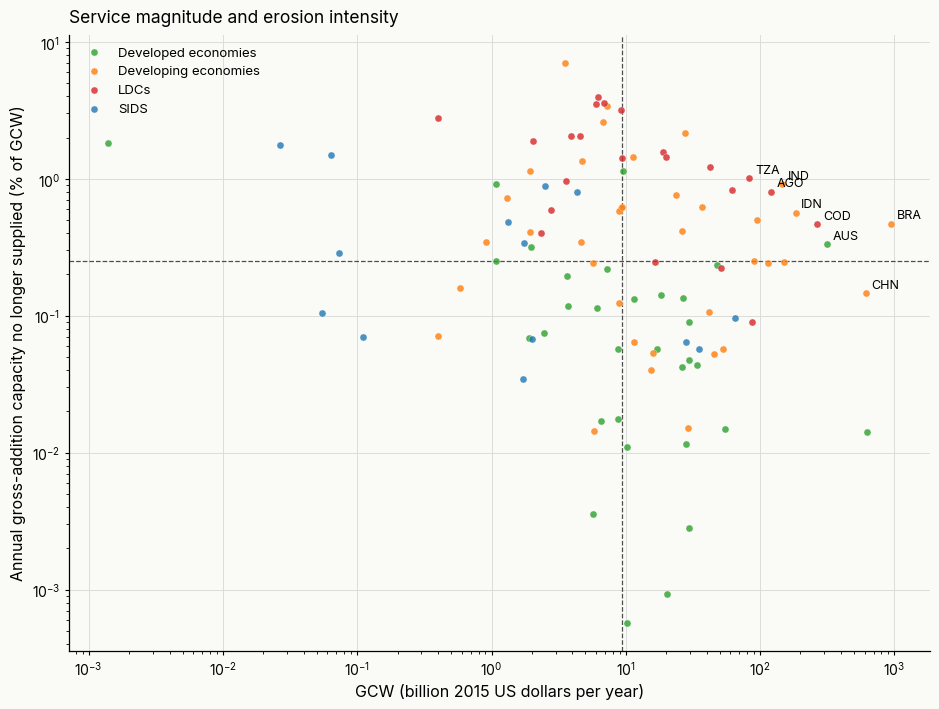

In [11]:
# A3 - typologie service contre érosion, panneau unique
fig, ax = plt.subplots(figsize=(9.5, 7.2), facecolor=BG)
clean(ax, grid_axis="both", spines=("left", "bottom"))
for g_name, d in t.groupby("groups"):
    ax.scatter(d["gcw_usd2015_yr_mean"] / 1e9, d["erosion_pct"], s=26, alpha=0.8,
               color=GROUP_COLORS.get(g_name, "grey"), label=g_name,
               edgecolor="white", linewidth=0.3, zorder=3)
for _, row in t.nlargest(8, "loss_usd").iterrows():
    ax.annotate(row["iso3"], (row["gcw_usd2015_yr_mean"] / 1e9, row["erosion_pct"]),
                fontsize=9, color=TEXT, xytext=(4, 4), textcoords="offset points")
ax.axvline(med_g / 1e9, color=MUTED, ls="--", lw=0.9)
ax.axhline(med_e, color=MUTED, ls="--", lw=0.9)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("GCW (billion 2015 US dollars per year)")
ax.set_ylabel("Annual gross-addition capacity no longer supplied (% of GCW)")
ax.legend(frameon=False, fontsize=9.5, loc="upper left")
panel(ax, "", "Service magnitude and erosion intensity")
fig.tight_layout()
save(fig, "Annex3_service_and_erosion")
plt.show()

<>:12: SyntaxWarning: invalid escape sequence '\$'
<>:12: SyntaxWarning: invalid escape sequence '\$'
<temporary-folder>\ipykernel_13556\2036569388.py:12: SyntaxWarning: invalid escape sequence '\$'
  ax.set_xlabel(f"Billion 2015 US dollars per year, at US\${PRICE:.0f} per tCO$_2$")


[saved] Annex4_who_pays.png / Annex4_who_pays.pdf


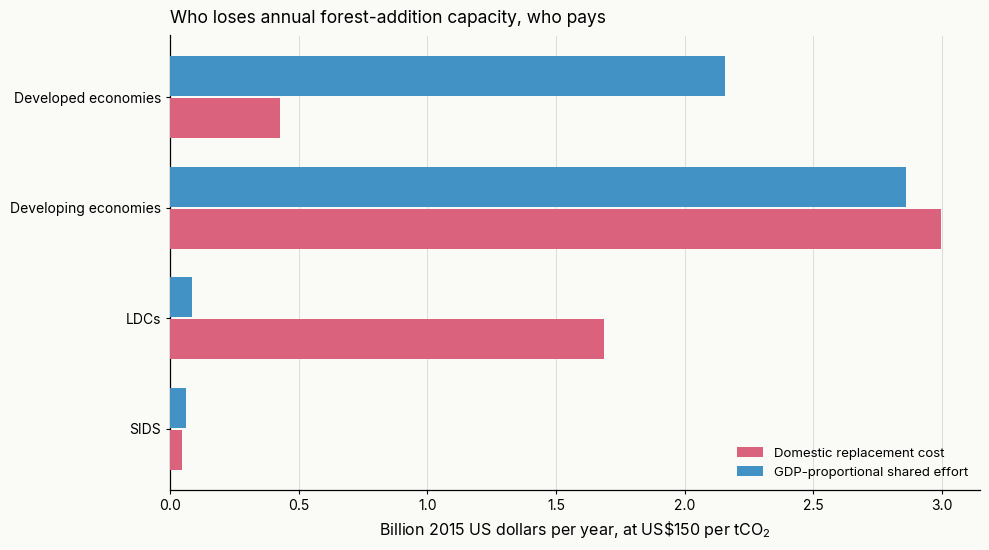

In [12]:
# A4 - qui perd la capacité annuelle, qui paie
fig, ax = plt.subplots(figsize=(10, 5.6), facecolor=BG)
clean(ax, grid_axis="x", spines=("left", "bottom"))
pos = np.arange(len(by_group))
ax.barh(pos + 0.19, by_group["cost_domestic"] / 1e9, 0.36, color=PINK,
        label="Domestic replacement cost", zorder=3)
ax.barh(pos - 0.19, by_group["cost_shared"] / 1e9, 0.36, color=OCEAN_COLS[2],
        label="GDP-proportional shared effort", zorder=3)
ax.set_yticks(pos)
ax.set_yticklabels(by_group.index, fontsize=10)
ax.invert_yaxis()
ax.set_xlabel(f"Billion 2015 US dollars per year, at US\${PRICE:.0f} per tCO$_2$")
ax.legend(frameon=False, fontsize=9.5, loc="lower right")
panel(ax, "", "Who loses annual forest-addition capacity, who pays")
fig.tight_layout()
save(fig, "Annex4_who_pays")
plt.show()

## Ce qui reste à trancher avant usage dans le manuscrit

| Point | Où | À faire |
|---|---|---|
| Prix de compensation | Figure 4 | Remplacer les 150 US$/tCO₂ par un prix AR6 converti en dollars 2015  |
| Seuil vert/bleu | Figure 2a | Valider les bornes de classes 20/40/60/80 % |
| Bornes de classes des cartes | Figures 1a, 3a | Valider les seuils, et vérifier qu'aucune classe ne reste vide |
| Unités « forêt seule » | Figure 2a | 61 unités sans composante bleue : couleur distincte, à confirmer en légende |
| Cumul de la figure 3c | Figure 3c | Le cumul suppose le rythme actuel maintenu : à dire en légende |
| Taïwan, zones contestées | Toutes les cartes | Mentionner l'agrégation et les exclusions en légende |